In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Unzip from Drive straight to Colab's high-speed local storage
!unzip -q "/content/drive/MyDrive/Colab Notebooks/covid detection/archive.zip" -d "/content/dataset/"

Mounted at /content/drive


In [2]:
import os
import tensorflow as tf
import keras
from keras.layers import Dense, Dropout, GlobalAveragePooling2D
from keras.applications import ResNet50
from keras.applications.resnet50 import preprocess_input
from keras.models import Model, Sequential
from keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
# Define paths and constants
TRAIN_DIR = 'dataset/Data/train/'
TEST_DIR = 'dataset/Data/test/'
IMG_SIZE = (224, 224)  # ResNet50 expected input size
BATCH_SIZE = 32
NUM_CLASSES = 3        # COVID19, NORMAL, PNEUMONIA

In [4]:
# Setup ImageDataGenerators with ResNet50 preprocessing
# Data Augmentation for training to prevent overfitting
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # Custom ResNet50 scaling
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only preprocessing (no augmentation) for testing/validation
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [5]:
# Load data from directories
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 5144 images belonging to 3 classes.
Found 1288 images belonging to 3 classes.


In [6]:
# Build ResNet50 Transfer Learning Model
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base ResNet layers
base_model.trainable = False

# Build custom network head
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),  # Reduces overfitting on medical images
    Dense(NUM_CLASSES, activation='softmax')
])
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,027 (91.98 MB)

 Trainable params: 525,315 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
# Compile Model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
# Train the Model
epochs = 10
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    validation_data=test_generator,
    validation_steps=test_generator.samples // BATCH_SIZE,
    epochs=epochs
)

Epoch 1/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.8736 - loss: 0.3767 - val_accuracy: 0.9203 - val_loss: 0.1861
Epoch 2/10
  1/160 ━━━━━━━━━━━━━━━━━━━━ 14s 92ms/step - accuracy: 0.9375 - loss: 0.2512

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


160/160 ━━━━━━━━━━━━━━━━━━━━ 17s 106ms/step - accuracy: 0.9375 - loss: 0.2512 - val_accuracy: 0.9172 - val_loss: 0.2023
Epoch 3/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 147s 921ms/step - accuracy: 0.9294 - loss: 0.1903 - val_accuracy: 0.9391 - val_loss: 0.1521
Epoch 4/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 19s 118ms/step - accuracy: 0.9062 - loss: 0.2039 - val_accuracy: 0.9406 - val_loss: 0.1515
Epoch 5/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 145s 905ms/step - accuracy: 0.9354 - loss: 0.1714 - val_accuracy: 0.9094 - val_loss: 0.2231
Epoch 6/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 18s 111ms/step - accuracy: 0.9062 - loss: 0.3325 - val_accuracy: 0.9086 - val_loss: 0.2247
Epoch 7/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 146s 912ms/step - accuracy: 0.9444 - loss: 0.1565 - val_accuracy: 0.9102 - val_loss: 0.2161
Epoch 8/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 17s 107ms/step - accuracy: 0.9688 - loss: 0.1482 - val_accuracy: 0.8961 - val_loss: 0.2415
Epoch 9/10
160/160 ━━━━━━━━━━━━━━━━━━━━ 146s 911ms/step - accuracy: 0.9474 - loss: 0.1448 -

41/41 ━━━━━━━━━━━━━━━━━━━━ 21s 484ms/step - accuracy: 0.9542 - loss: 0.1321

Test Loss: 0.1321
Test Accuracy: 95.42%
41/41 ━━━━━━━━━━━━━━━━━━━━ 32s 465ms/step

Classification Report:
              precision    recall  f1-score   support

     COVID19       1.00      0.91      0.95       116
      NORMAL       0.88      0.95      0.91       317
   PNEUMONIA       0.98      0.96      0.97       855

    accuracy                           0.95      1288
   macro avg       0.95      0.94      0.95      1288
weighted avg       0.96      0.95      0.95      1288



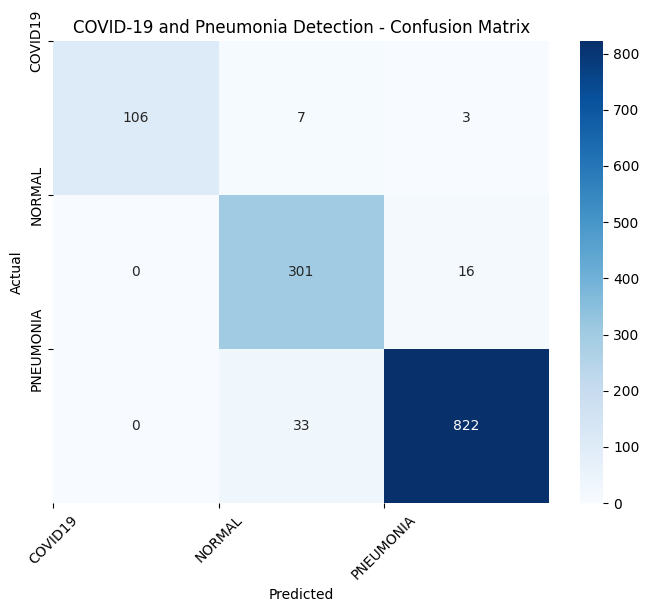

In [9]:
import numpy as np
import seaborn as sns
import sklearn.metrics as metrics
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# Overall Performance Evaluation
loss, accuracy = model.evaluate(test_generator)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Get deep predictions for Medical Metrics
# Reset generator to start from the beginning
test_generator.reset()
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# True labels
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())  # e.g., ['COVID19', 'NORMAL', 'PNEUMONIA']

# Print Classification Report (Precision, Recall, F1-score)
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# Plotting Confusion Matrix
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('COVID-19 and Pneumonia Detection - Confusion Matrix')
tick_marks = np.arange(len(class_labels))
plt.xticks(tick_marks, class_labels, rotation=45)
plt.yticks(tick_marks, class_labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [16]:
# Save the trained model
model.save('covid_pneumonia_resnet50_model.keras')
print("Model saved successfully!")

Model saved successfully!
